# 04. Phân tích dữ liệu và xử lý mất cân bằng
Dữ liệu sạch từ notebook 03 vẫn **mất cân bằng mạnh** theo nhiều chiều: loại nhà, khu vực, phân khúc giá, nguồn. Với bài toán hồi quy, mất cân bằng làm mô hình học tốt nhóm đông (nhà ở Hà Nội/TP.HCM, giá 3–10 tỷ) và dự đoán kém nhóm hiếm (shophouse, tỉnh lẻ, nhà rất rẻ/rất đắt). Notebook này:

1. Đo mức mất cân bằng theo từng chiều
2. Phân tích quan hệ giữa giá và các đặc trưng chính
3. Xử lý: biến đổi log cho biến mục tiêu, **chia tập phân tầng** theo (loại nhà × vùng × phân khúc giá), **trọng số mẫu nghịch tần suất**, và chuẩn bị **tập tăng mẫu nhóm hiếm** để so sánh ở notebook 06

In [1]:
import sys, os
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from can_bang import *

pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures'
df = pd.read_parquet('../data/processed/du_lieu_sach.parquet')
df['vung'] = vung(df['tinh'])
df['phan_khuc'] = phan_khuc_gia(df['gia_vnd'])
df['nam'] = df['ngay_dang'].dt.year
print(df.shape)

(863524, 32)


## 1. Biến mục tiêu: giá lệch phải rất mạnh

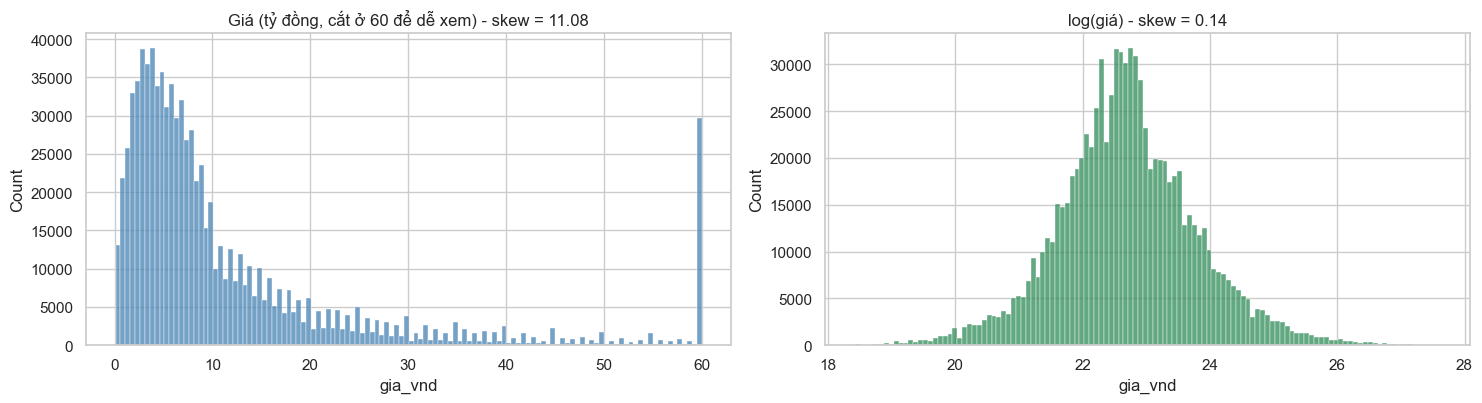

count    863524.00
mean         14.04
std          29.70
min           0.10
1%            0.49
5%            1.27
25%           3.75
50%           7.00
75%          13.80
95%          45.50
99%         125.00
max        1000.00


In [2]:
y = df['gia_vnd'] / 1e9
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.histplot(y.clip(upper=60), bins=120, ax=ax[0], color='steelblue')
ax[0].set_title(f'Giá (tỷ đồng, cắt ở 60 để dễ xem) - skew = {skew(y):.2f}')
sns.histplot(np.log(df['gia_vnd']), bins=120, ax=ax[1], color='seagreen')
ax[1].set_title(f'log(giá) - skew = {skew(np.log(df["gia_vnd"])):.2f}')
plt.tight_layout(); plt.savefig(f'{FIG}/04_bien_muc_tieu.png', dpi=120); plt.show()
print(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2).to_string())

## 2. Mức độ mất cân bằng theo từng chiều
Tỉ số mất cân bằng (IR) = số mẫu nhóm lớn nhất / số mẫu nhóm nhỏ nhất.

In [3]:
def bang_phan_bo(cot, ten):
    dem = df[cot].value_counts()
    return pd.DataFrame({'Số mẫu': dem, 'Tỉ lệ (%)': (dem / len(df) * 100).round(2)}).rename_axis(ten)

for cot, ten in [('loai_bds', 'Loại BĐS'), ('vung', 'Vùng'), ('phan_khuc', 'Phân khúc giá'), ('nguon', 'Nguồn')]:
    b = bang_phan_bo(cot, ten)
    print(f'--- {ten}: IR = {b["Số mẫu"].max() / b["Số mẫu"].min():,.0f}')
    print(b.to_string(), '\n')
dem_tinh = df['tinh'].value_counts()
print(f'34 tỉnh: Hà Nội + TP.HCM chiếm {dem_tinh.iloc[:2].sum() / len(df):.1%}; 20 tỉnh ít nhất cộng lại chỉ có {dem_tinh.iloc[-20:].sum():,} mẫu ({dem_tinh.iloc[-20:].sum() / len(df):.2%})')
dem_quan = df.groupby(['tinh', 'quan_huyen']).size()
print(f'{len(dem_quan)} quận/huyện: {(dem_quan < 30).sum()} quận có dưới 30 mẫu, {(dem_quan < 100).sum()} quận dưới 100 mẫu')

--- Loại BĐS: IR = 40
                  Số mẫu  Tỉ lệ (%)
Loại BĐS                           
Nhà ở             473052      54.78
Đất               203659      23.58
Căn hộ            121744      14.10
Biệt thự/Liền kề   53366       6.18
Shophouse          11703       1.36 

--- Vùng: IR = 9
             Số mẫu  Tỉ lệ (%)
Vùng                          
Hồ Chí Minh  345253      39.98
Hà Nội       319612      37.01
Tỉnh khác    158128      18.31
Đà Nẵng       40531       4.69 

--- Phân khúc giá: IR = 6
               Số mẫu  Tỉ lệ (%)
Phân khúc giá                   
5–8 tỷ         182452      21.13
8–15 tỷ        179518      20.79
3–5 tỷ         145249      16.82
15–30 tỷ       117114      13.56
> 30 tỷ         79960       9.26
2–3 tỷ          72121       8.35
1–2 tỷ          56216       6.51
< 1 tỷ          30894       3.58 

--- Nguồn: IR = 70
       Số mẫu  Tỉ lệ (%)
Nguồn                   
1      594564      68.85
2      138211      16.01
3       53955       6.25
4       42544    

656 quận/huyện: 256 quận có dưới 30 mẫu, 384 quận dưới 100 mẫu


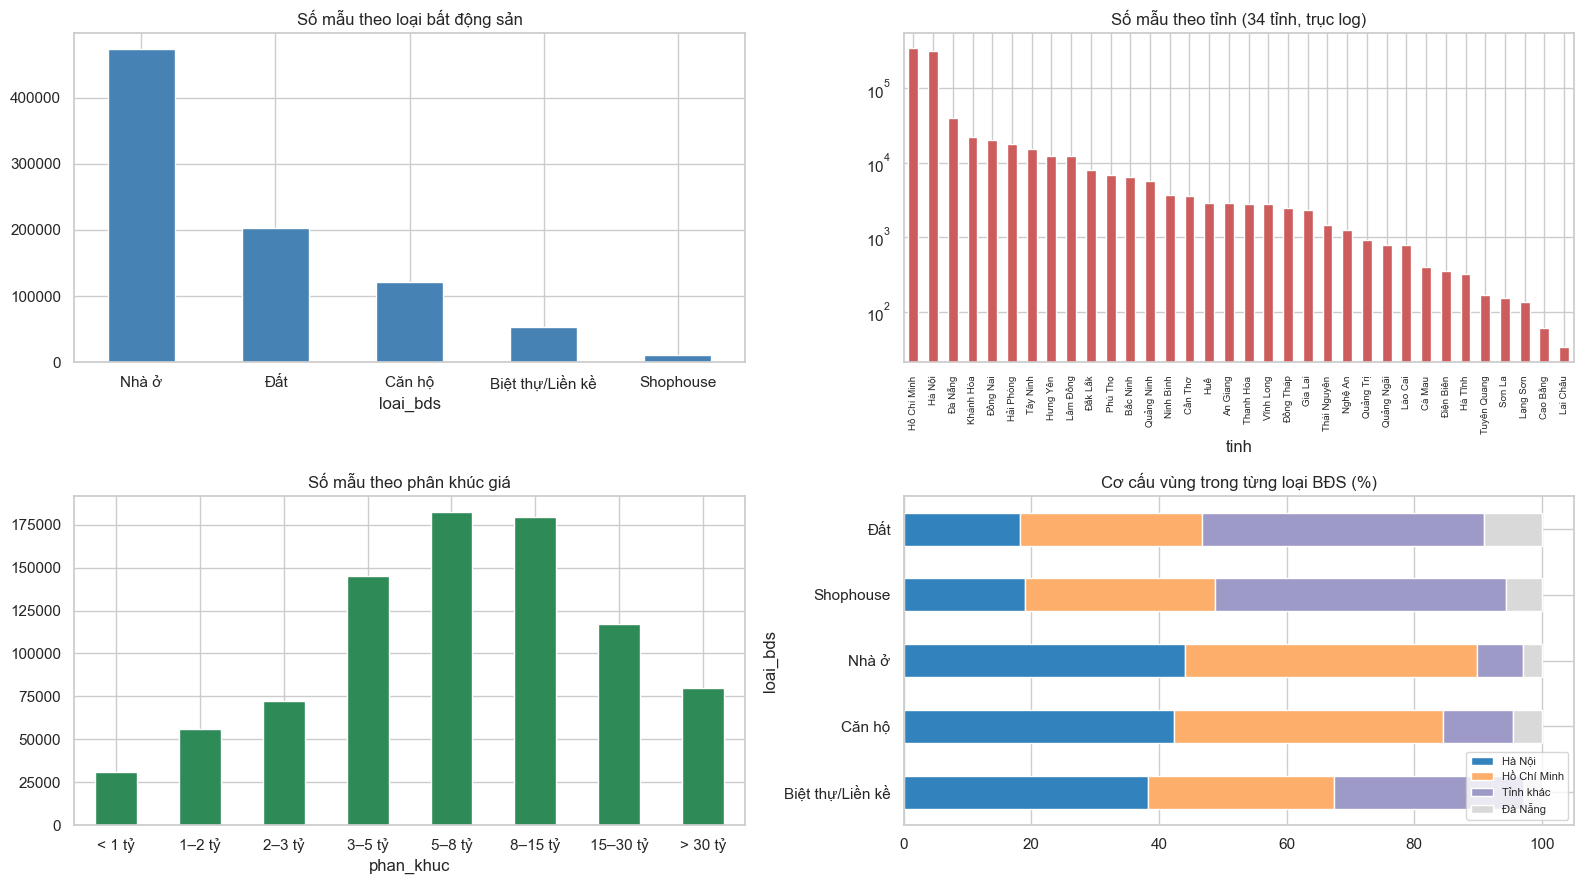

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
df['loai_bds'].value_counts().plot(kind='bar', ax=ax[0, 0], color='steelblue', rot=0); ax[0, 0].set_title('Số mẫu theo loại bất động sản')
dem_tinh.plot(kind='bar', ax=ax[0, 1], color='indianred', logy=True); ax[0, 1].set_title('Số mẫu theo tỉnh (34 tỉnh, trục log)')
ax[0, 1].tick_params(axis='x', labelsize=7)
df['phan_khuc'].value_counts().sort_index().plot(kind='bar', ax=ax[1, 0], color='seagreen', rot=0); ax[1, 0].set_title('Số mẫu theo phân khúc giá')
pd.crosstab(df['loai_bds'], df['vung'], normalize='index').mul(100).plot(kind='barh', stacked=True, ax=ax[1, 1], colormap='tab20c')
ax[1, 1].set_title('Cơ cấu vùng trong từng loại BĐS (%)'); ax[1, 1].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(f'{FIG}/04_mat_can_bang.png', dpi=120); plt.show()

## 3. Quan hệ giữa giá và các đặc trưng chính

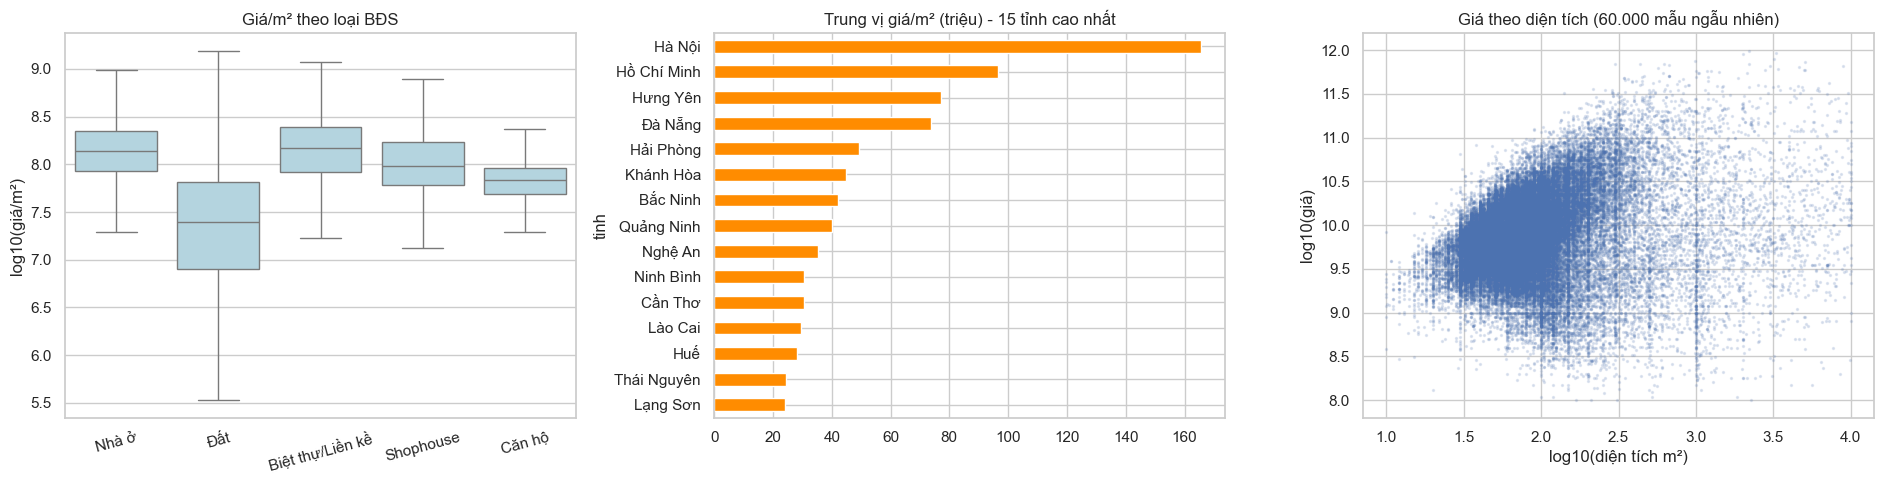

In [5]:
mau = df.sample(60000, random_state=42)
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.boxplot(data=df, x='loai_bds', y=np.log10(df['gia_m2']), ax=ax[0], showfliers=False, color='lightblue')
ax[0].set_ylabel('log10(giá/m²)'); ax[0].set_xlabel(''); ax[0].set_title('Giá/m² theo loại BĐS'); ax[0].tick_params(axis='x', rotation=15)
top = df.groupby('tinh')['gia_m2'].median().sort_values(ascending=False).head(15) / 1e6
top.sort_values().plot(kind='barh', ax=ax[1], color='darkorange'); ax[1].set_title('Trung vị giá/m² (triệu) - 15 tỉnh cao nhất')
ax[2].scatter(np.log10(mau['dien_tich_m2']), np.log10(mau['gia_vnd']), s=2, alpha=0.15)
ax[2].set_xlabel('log10(diện tích m²)'); ax[2].set_ylabel('log10(giá)'); ax[2].set_title('Giá theo diện tích (60.000 mẫu ngẫu nhiên)')
plt.tight_layout(); plt.savefig(f'{FIG}/04_quan_he_gia.png', dpi=120); plt.show()

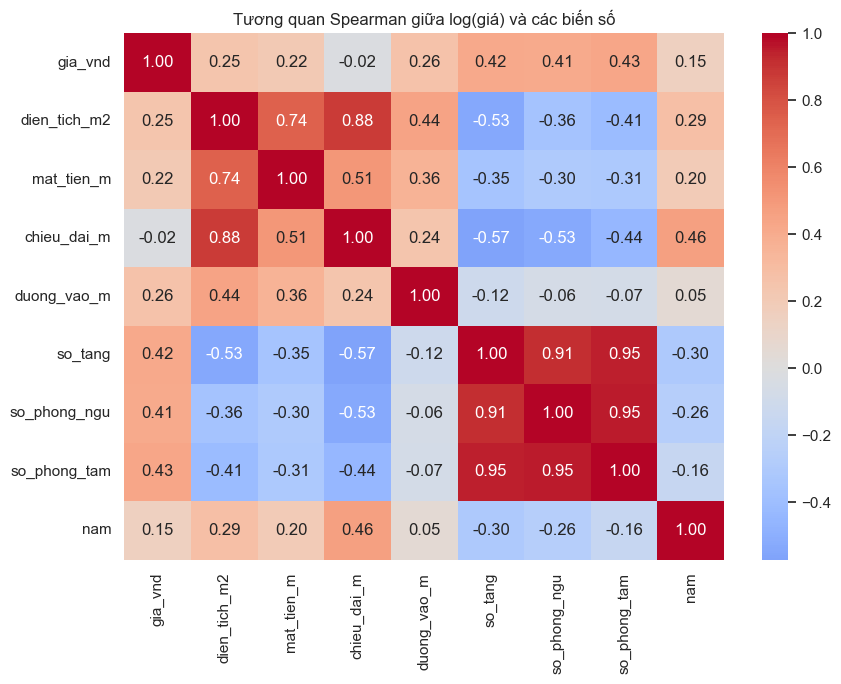

Trung vị giá/m² (triệu) theo năm đăng: {2019.0: 102.2, 2020.0: 91.7, 2022.0: 89.6, 2023.0: 100.3, 2024.0: 112.5, 2025.0: 95.0}


In [6]:
so = df[['gia_vnd', 'dien_tich_m2', 'mat_tien_m', 'chieu_dai_m', 'duong_vao_m', 'so_tang', 'so_phong_ngu', 'so_phong_tam', 'nam']].copy()
so['gia_vnd'] = np.log(so['gia_vnd']); so['dien_tich_m2'] = np.log(so['dien_tich_m2'])
plt.figure(figsize=(9, 7))
sns.heatmap(so.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Tương quan Spearman giữa log(giá) và các biến số')
plt.tight_layout(); plt.savefig(f'{FIG}/04_tuong_quan.png', dpi=120); plt.show()
print('Trung vị giá/m² (triệu) theo năm đăng:', (df.groupby('nam')['gia_m2'].median() / 1e6).round(1).to_dict())

## 4. Xử lý mất cân bằng
### 4a. Biến đổi log cho biến mục tiêu
Độ lệch của giá giảm từ khoảng 7 xuống gần 0 (mục 1) – mô hình không còn bị vài căn hàng trăm tỷ chi phối sai số.

### 4b. Chia tập phân tầng 70/15/15
Tầng = loại BĐS × vùng × phân khúc giá. Tầng có dưới 20 mẫu được gộp lại để vẫn chia phân tầng được. Nhờ vậy nhóm hiếm có mặt đủ ở cả 3 tập và tỉ lệ các nhóm giống nhau giữa train/val/test.

In [7]:
df['tang'] = tang(df)
dem_tang = df['tang'].value_counts()
df['tang_chia'] = df['tang'].where(df['tang'].map(dem_tang) >= 20, 'Tầng hiếm (gộp)')
print('Số tầng:', df['tang'].nunique(), '| tầng ít mẫu bị gộp:', int((dem_tang < 20).sum()), f'({int(dem_tang[dem_tang < 20].sum())} mẫu)')
train, tam = train_test_split(df, test_size=0.30, stratify=df['tang_chia'], random_state=42)
val, test = train_test_split(tam, test_size=0.50, stratify=tam['tang_chia'], random_state=42)
print('train / val / test:', len(train), len(val), len(test))
kiem_tra = pd.concat({ten: t['loai_bds'].value_counts(normalize=True).mul(100).round(2) for ten, t in [('train', train), ('val', val), ('test', test)]}, axis=1)
kiem_tra.join(pd.concat({ten: t['vung'].value_counts(normalize=True).mul(100).round(2) for ten, t in [('train', train), ('val', val), ('test', test)]}, axis=1), how='outer', rsuffix='_vung')

Số tầng: 156 | tầng ít mẫu bị gộp: 14 (112 mẫu)


train / val / test: 604466 129529 129529


,train,val,test,train_vung,val_vung,test_vung
Biệt thự/Liền kề,6.18,6.18,6.18,NaN,NaN,NaN
Căn hộ,14.10,14.10,14.10,NaN,NaN,NaN
Hà Nội,NaN,NaN,NaN,37.01,37.01,37.01
Hồ Chí Minh,NaN,NaN,NaN,39.98,39.98,39.98
Nhà ở,54.78,54.78,54.78,NaN,NaN,NaN
Shophouse,1.36,1.36,1.35,NaN,NaN,NaN
Tỉnh khác,NaN,NaN,NaN,18.31,18.31,18.31
Đà Nẵng,NaN,NaN,NaN,4.69,4.69,4.69
Đất,23.58,23.58,23.59,NaN,NaN,NaN


In [8]:
pd.concat({ten: t['phan_khuc'].value_counts(normalize=True).sort_index().mul(100).round(2) for ten, t in [('train', train), ('val', val), ('test', test)]}, axis=1).rename_axis('Phân khúc giá (%)')

,train,val,test
Phân khúc giá (%),,,
< 1 tỷ,3.58,3.58,3.58
1–2 tỷ,6.51,6.51,6.51
2–3 tỷ,8.35,8.35,8.35
3–5 tỷ,16.82,16.82,16.82
5–8 tỷ,21.13,21.13,21.13
8–15 tỷ,20.79,20.79,20.79
15–30 tỷ,13.56,13.56,13.56
> 30 tỷ,9.26,9.26,9.26


### 4c. Trọng số mẫu nghịch tần suất (chỉ tính trên tập train)
$w_i = (1 / p_{tầng(i)})^{0.5}$, chuẩn hoá trung bình 1 và cắt trong [0.2, 5] để không mẫu nào bị phóng quá mạnh. Lấy căn bậc hai để giảm mức chênh (cân bằng hoàn toàn sẽ làm nhiễu nhóm rất nhỏ bị khuếch đại).

In [9]:
train = train.copy()
train['trong_so'] = trong_so_nghich_tan_suat(train['tang'])
for t in (val, test):
    t['trong_so'] = 1.0
tong_w = train.groupby('loai_bds').agg(so_mau=('trong_so', 'size'), tong_trong_so=('trong_so', 'sum'))
tong_w['% số mẫu'] = (tong_w['so_mau'] / tong_w['so_mau'].sum() * 100).round(1)
tong_w['% tổng trọng số'] = (tong_w['tong_trong_so'] / tong_w['tong_trong_so'].sum() * 100).round(1)
print(train['trong_so'].describe().round(3).to_string())
tong_w[['so_mau', '% số mẫu', '% tổng trọng số']]

count    604466.000
mean          1.000
std           0.734
min           0.410
25%           0.486
50%           0.736
75%           1.232
max           5.084


,so_mau,% số mẫu,% tổng trọng số
loai_bds,,,
Biệt thự/Liền kề,37355,6.2,11.0
Căn hộ,85222,14.1,18.7
Nhà ở,331134,54.8,37.1
Shophouse,8193,1.4,5.0
Đất,142562,23.6,28.2


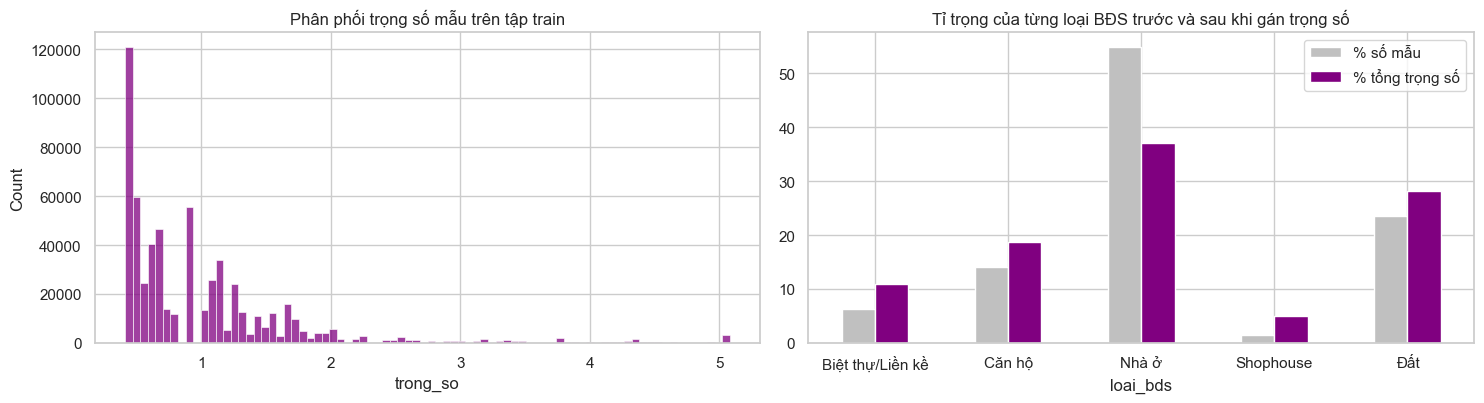

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.histplot(train['trong_so'], bins=80, ax=ax[0], color='purple'); ax[0].set_title('Phân phối trọng số mẫu trên tập train')
tong_w[['% số mẫu', '% tổng trọng số']].plot(kind='bar', ax=ax[1], rot=0, color=['silver', 'purple'])
ax[1].set_title('Tỉ trọng của từng loại BĐS trước và sau khi gán trọng số')
plt.tight_layout(); plt.savefig(f'{FIG}/04_trong_so.png', dpi=120); plt.show()

### 4d. Tập tăng mẫu nhóm hiếm (random oversampling có nhiễu nhỏ)
Tầng nào ít hơn 2.000 mẫu trong tập train thì nhân bản ngẫu nhiên lên 2.000 mẫu, cộng nhiễu ±2% vào các biến kích thước để không trùng y hệt. **Chỉ áp dụng cho tập train**, tập val/test giữ nguyên để đánh giá trung thực. Notebook 06 sẽ so sánh 3 cách: không xử lý, trọng số mẫu, tăng mẫu.

In [11]:
train_tang_mau = tang_mau_nhom_hiem(train.drop(columns=['trong_so']), train['tang'], muc_toi_thieu=2000,
                                    cot_so=['dien_tich_m2', 'mat_tien_m', 'chieu_dai_m', 'duong_vao_m'])
train_tang_mau['gia_m2'] = train_tang_mau['gia_vnd'] / train_tang_mau['dien_tich_m2']
print('Tập train gốc:', len(train), '-> sau tăng mẫu:', len(train_tang_mau))
so_sanh = pd.concat({'train gốc': train['loai_bds'].value_counts(normalize=True), 'sau tăng mẫu': train_tang_mau['loai_bds'].value_counts(normalize=True)}, axis=1).mul(100).round(2)
so_sanh

Tập train gốc: 604466 -> sau tăng mẫu: 738661


,train gốc,sau tăng mẫu
loai_bds,,
Nhà ở,54.78,46.65
Đất,23.58,20.15
Căn hộ,14.10,15.31
Biệt thự/Liền kề,6.18,9.77
Shophouse,1.36,8.12


In [12]:
os.makedirs('../data/processed', exist_ok=True)
COT_BO = ['tang_chia']
train.drop(columns=COT_BO).to_parquet('../data/processed/train.parquet', index=False)
val.drop(columns=COT_BO).to_parquet('../data/processed/val.parquet', index=False)
test.drop(columns=COT_BO).to_parquet('../data/processed/test.parquet', index=False)
train_tang_mau.drop(columns=COT_BO).to_parquet('../data/processed/train_tang_mau.parquet', index=False)
for f in ['train', 'val', 'test', 'train_tang_mau']:
    print(f, round(os.path.getsize(f'../data/processed/{f}.parquet') / 1e6, 1), 'MB')

train 49.8 MB
val 10.8 MB
test 10.8 MB
train_tang_mau 57.3 MB
